<a href="https://colab.research.google.com/github/samueladian3-cpu/ml-portfolio/blob/main/aml_prediction_kelompok_Data_mining_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NAMA KELOMPOK :
1. ANGELI LORENSA WIRLIN  (23120182)
2. FHENDHY O. D. NOMLENI  (23120106)
3. YUDHA HABEL PALULUN    (23120040)
4. SAMUEL ADIAN           (23120039)
5. Rivaldi Christian Adoe (23120075)

## Problem Statement & Dataset Description

Money laundering remains a significant global issue, driving the need for improved transaction monitoring methods. Current anti-money laundering (AML) procedures are inefficient, and access to data is difficult/restricted by legal and privacy issues. Moreover, existing data often lacks diversity and true labels. This study introduces a novel AML transaction generator, creating the SAML-D dataset with enhanced features and typologies, aiming to aid researchers in evaluating their models and developing more advanced monitoring methods.

The dataset incorporates 12 features and 28 typologies (split between 11 normal and 17 suspicious). These were selected based on existing datasets, the academic literature, and interviews with AML specialists. The dataset comprises 9,504,852 transactions, of which 0.1039% are suspicious. It also includes 15 graphical network structures to represent the transaction flow within these typologies. The structures, while sometimes shared among typologies, vary significantly in parameters to increase complexities and challenge detection efforts. More details about these typologies are available in the paper above. The dataset is an updated version compared to the paper.

Features of the SAML-D dataset:

• Time and Date: Essential for tracking transaction chronology.

• Sender and Receiver Account Details: Helps uncover behavioural patterns and complex banking connections.

• Amount: Indicates transaction values to identify suspicious activities.

• Payment Type: Includes various methods like credit card, debit card, cash, ACH transfers, cross-border, and cheque.

• Sender and Receiver Bank Location: Pinpoints high-risk regions including Mexico, Turkey, Morocco, and the UAE.

• Payment and Receiver Currency: Align with location features, adding complexity when mismatched.

• 'Is Suspicious' Feature: Binary indicator differentiating normal from suspicious transactions.

• Type: Classifies typologies, offering deeper insights.

## Importing Libraries

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import math
from PIL import Image
from scipy.stats import skew
from matplotlib.transforms import Bbox
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, RobustScaler

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import f1_score

## Load the Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

raw_df = pd.read_csv("/content/drive/MyDrive/Fraud.csv")
raw_df.shape

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(6362620, 11)

In [ ]:
df = raw_df.sample(n=100000, random_state=1)

df.shape

(100000, 11)

## Exploratory Data Analysis

In [ ]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6322570,688,CASH_IN,23557.12,C867750533,8059.00,31616.12,C1026934669,169508.66,145951.53,0,0
3621196,274,PAYMENT,6236.13,C601099070,0.00,0.00,M701283411,0.00,0.00,0,0
1226256,133,PAYMENT,33981.87,C279540931,18745.72,0.00,M577905776,0.00,0.00,0,0
2803274,225,CASH_OUT,263006.42,C11675531,20072.00,0.00,C529577791,390253.56,653259.98,0,0
3201247,249,CASH_OUT,152013.74,C530649214,20765.00,0.00,C1304175579,252719.19,404732.93,0,0


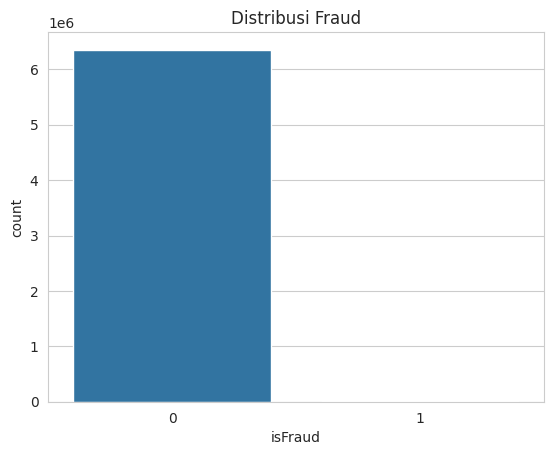

In [ ]:
sns.countplot(data=raw_df, x='isFraud')
plt.title("Distribusi Fraud")
plt.show()

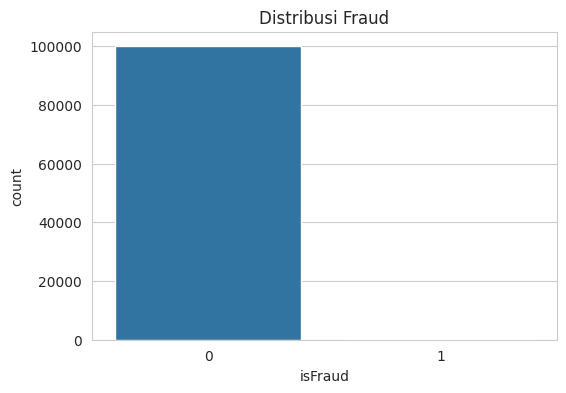

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='isFraud')
plt.title("Distribusi Fraud")
plt.show()

In [ ]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 6322570 to 4679267
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            100000 non-null  int64  
 1   type            100000 non-null  object 
 2   amount          100000 non-null  float64
 3   nameOrig        100000 non-null  object 
 4   oldbalanceOrg   100000 non-null  float64
 5   newbalanceOrig  100000 non-null  float64
 6   nameDest        100000 non-null  object 
 7   oldbalanceDest  100000 non-null  float64
 8   newbalanceDest  100000 non-null  float64
 9   isFraud         100000 non-null  int64  
 10  isFlaggedFraud  100000 non-null  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 9.2+ MB


## Converting features into datetime features

In [ ]:
# Konversi step ke waktu (jam)
df['hour'] = df['step'] % 24

# Hari (simulasi)
df['day'] = df['step'] // 24

# Transaksi malam
df['is_night'] = ((df['hour'] < 6) | (df['hour'] > 22)).astype(int)
# Selisih saldo
df['balance_diff_orig'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['balance_diff_dest'] = df['newbalanceDest'] - df['oldbalanceDest']

# Transaksi besar
df['is_large_amount'] = (df['amount'] > df['amount'].mean()).astype(int)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 6322570 to 4679267
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   step               100000 non-null  int64  
 1   type               100000 non-null  object 
 2   amount             100000 non-null  float64
 3   nameOrig           100000 non-null  object 
 4   oldbalanceOrg      100000 non-null  float64
 5   newbalanceOrig     100000 non-null  float64
 6   nameDest           100000 non-null  object 
 7   oldbalanceDest     100000 non-null  float64
 8   newbalanceDest     100000 non-null  float64
 9   isFraud            100000 non-null  int64  
 10  isFlaggedFraud     100000 non-null  int64  
 11  hour               100000 non-null  int64  
 12  day                100000 non-null  int64  
 13  is_night           100000 non-null  int64  
 14  balance_diff_orig  100000 non-null  float64
 15  balance_diff_dest  100000 non-null  float64
 16  

In [ ]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud', 'hour', 'day', 'is_night', 'balance_diff_orig',
       'balance_diff_dest', 'is_large_amount'],
      dtype='object')

In [ ]:
df.head(3)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour,day,is_night,balance_diff_orig,balance_diff_dest,is_large_amount
6322570,688,CASH_IN,23557.12,C867750533,8059.00,31616.12,C1026934669,169508.66,145951.53,0,0,16,28,0,-23557.12,-23557.13,0
3621196,274,PAYMENT,6236.13,C601099070,0.00,0.00,M701283411,0.00,0.00,0,0,10,11,0,0.00,0.00,0
1226256,133,PAYMENT,33981.87,C279540931,18745.72,0.00,M577905776,0.00,0.00,0,0,13,5,0,18745.72,0.00,0


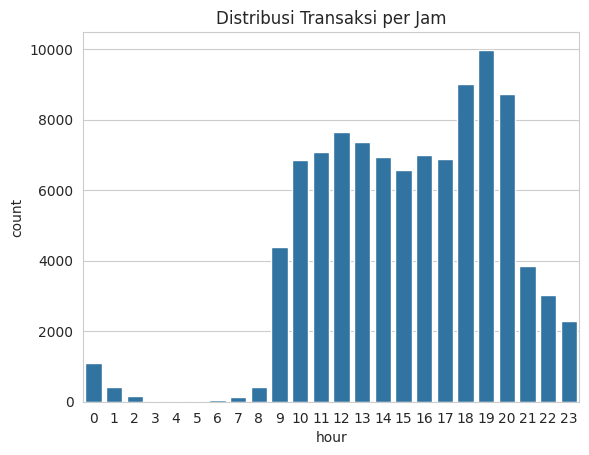

In [ ]:
sns.countplot(data=df, x='hour')
plt.title("Distribusi Transaksi per Jam")
plt.show()

In [ ]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud', 'hour', 'day', 'is_night', 'balance_diff_orig',
       'balance_diff_dest', 'is_large_amount'],
      dtype='object')

In [ ]:
summary = pd.DataFrame({
    'Total_Transactions': df['type'].value_counts(),
    'Fraud_Transactions': df[df['isFraud'] == 1].groupby('type').size()
}).fillna(0)

summary

,Total_Transactions,Fraud_Transactions
type,,
CASH_IN,21987,0.0
CASH_OUT,35209,64.0
DEBIT,694,0.0
PAYMENT,33694,0.0
TRANSFER,8416,60.0


In [ ]:
fraud_stats = df[df['isFraud'] == 1]['amount'].agg(['max', 'mean', 'min', 'median', 'std'])
normal_stats = df[df['isFraud'] == 0]['amount'].agg(['max', 'mean', 'min', 'median', 'std'])

print("Fraud Transactions Stats:\n", fraud_stats)
print("\nNormal Transactions Stats:\n", normal_stats)

Fraud Transactions Stats:
 max       1.000000e+07
mean      1.206723e+06
min       1.196500e+02
median    4.222958e+05
std       2.037003e+06
Name: amount, dtype: float64

Normal Transactions Stats:
 max       4.669816e+07
mean      1.802807e+05
min       1.800000e-01
median    7.530873e+04
std       6.119777e+05
Name: amount, dtype: float64


## Data Visualizations

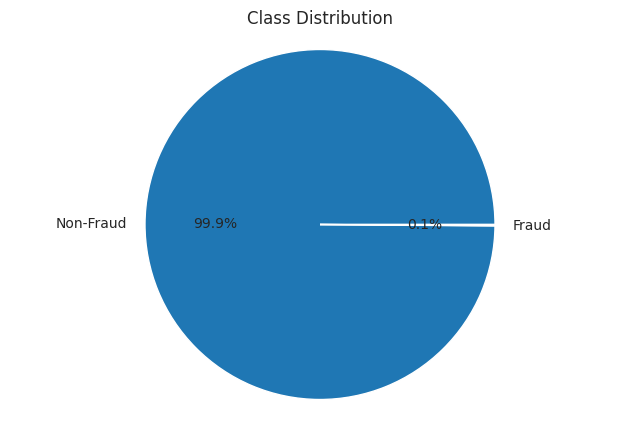

In [ ]:
class_distribution = df['isFraud'].value_counts()

plt.figure(figsize=(8, 5))
plt.pie(
    class_distribution,
    labels=['Non-Fraud', 'Fraud'],
    autopct='%1.1f%%'
)

plt.title('Class Distribution')
plt.axis('equal')
plt.show()

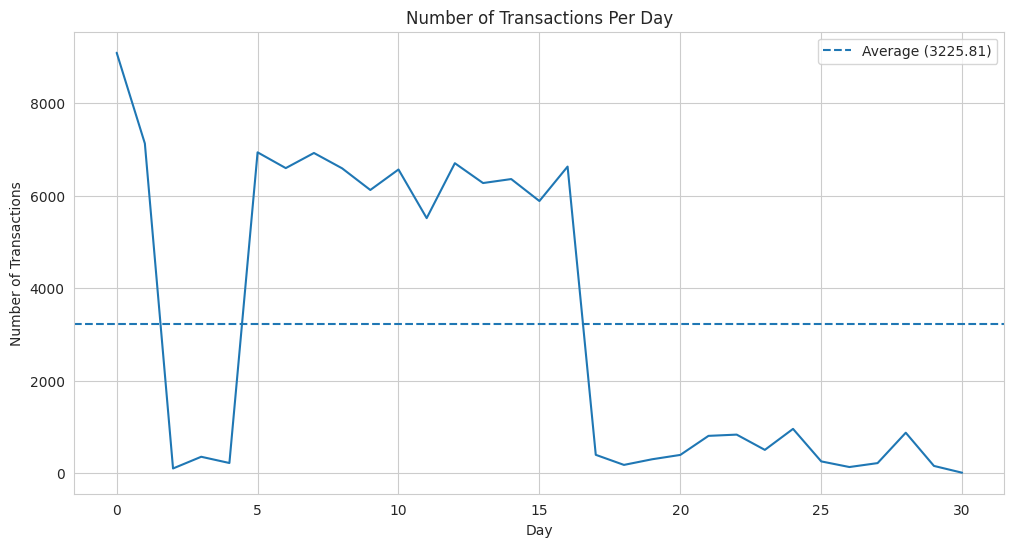

In [ ]:
df['day'] = df['step'] // 24

daily_transactions = df.groupby('day').size()

average_daily = daily_transactions.mean()

plt.figure(figsize=(12, 6))
daily_transactions.plot(kind='line')

plt.axhline(
    y=average_daily,
    linestyle='--',
    label=f'Average ({average_daily:.2f})'
)

plt.xlabel('Day')
plt.ylabel('Number of Transactions')
plt.title('Number of Transactions Per Day')
plt.legend()
plt.grid(True)
plt.show()

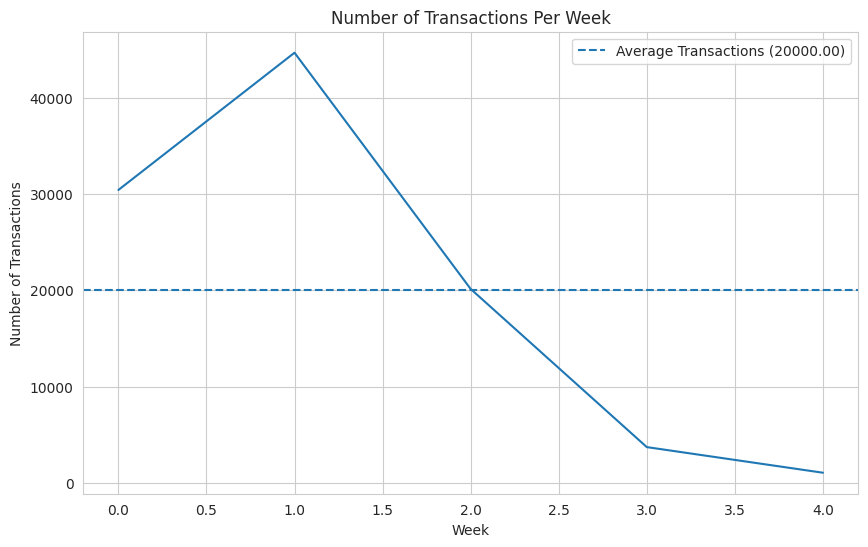

In [ ]:
df['day'] = df['step'] // 24

weekly_transactions = df.groupby(df['day'] // 7).size()

average_weekly_transactions = weekly_transactions.mean()

plt.figure(figsize=(10, 6))
weekly_transactions.plot(kind='line')
plt.axhline(y=average_weekly_transactions, linestyle='--', label=f'Average Transactions ({average_weekly_transactions:.2f})')
plt.xlabel('Week')
plt.ylabel('Number of Transactions')
plt.title('Number of Transactions Per Week')
plt.legend()
plt.grid(True)
plt.show()

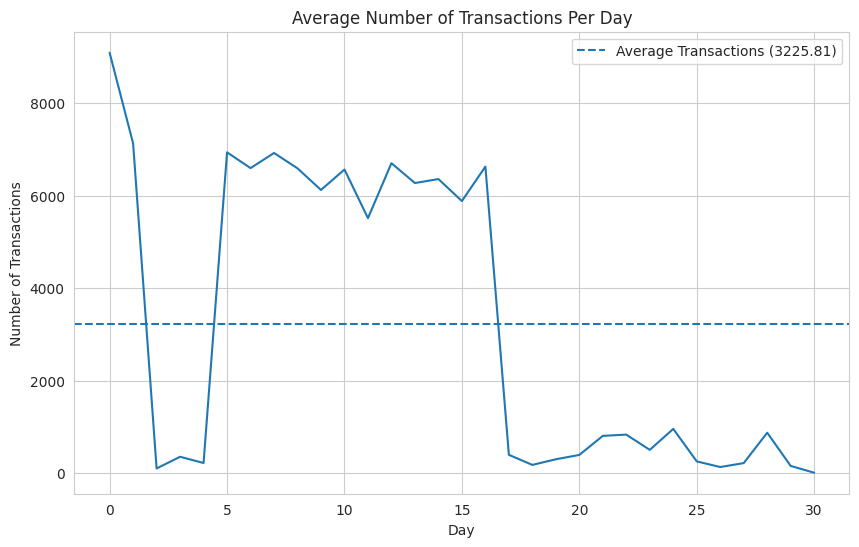

In [ ]:
df['day'] = df['step'] // 24

daily_transactions = df.groupby('day').size()

average_daily_transactions = daily_transactions.mean()

plt.figure(figsize=(10, 6))
daily_transactions.plot(kind='line')
plt.axhline(y=average_daily_transactions, linestyle='--', label=f'Average Transactions ({average_daily_transactions:.2f})')
plt.xlabel('Day')
plt.ylabel('Number of Transactions')
plt.title('Average Number of Transactions Per Day')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud', 'hour', 'day', 'is_night', 'balance_diff_orig',
       'balance_diff_dest', 'is_large_amount'],
      dtype='object')

In [ ]:
df['isFraud'].value_counts(normalize=True) * 100

,proportion
isFraud,
0,99.876
1,0.124


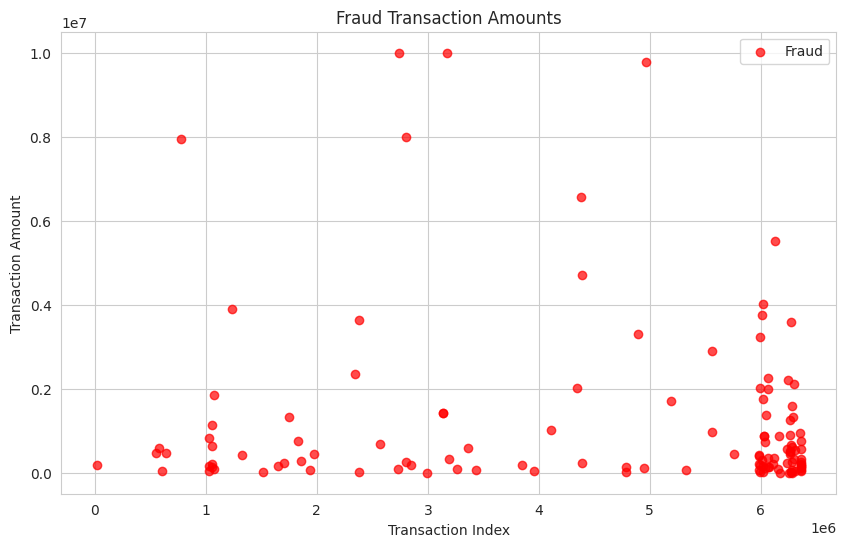

In [ ]:
# Separate the data
fraud_data = df[df['isFraud'] == 1]
non_fraud_data = df[df['isFraud'] == 0]

plt.figure(figsize=(10, 6))
plt.scatter(fraud_data.index, fraud_data['amount'], color='red', label='Fraud', alpha=0.7)

plt.title('Fraud Transaction Amounts')
plt.xlabel('Transaction Index')
plt.ylabel('Transaction Amount')
plt.legend()
plt.grid(True)
plt.show()

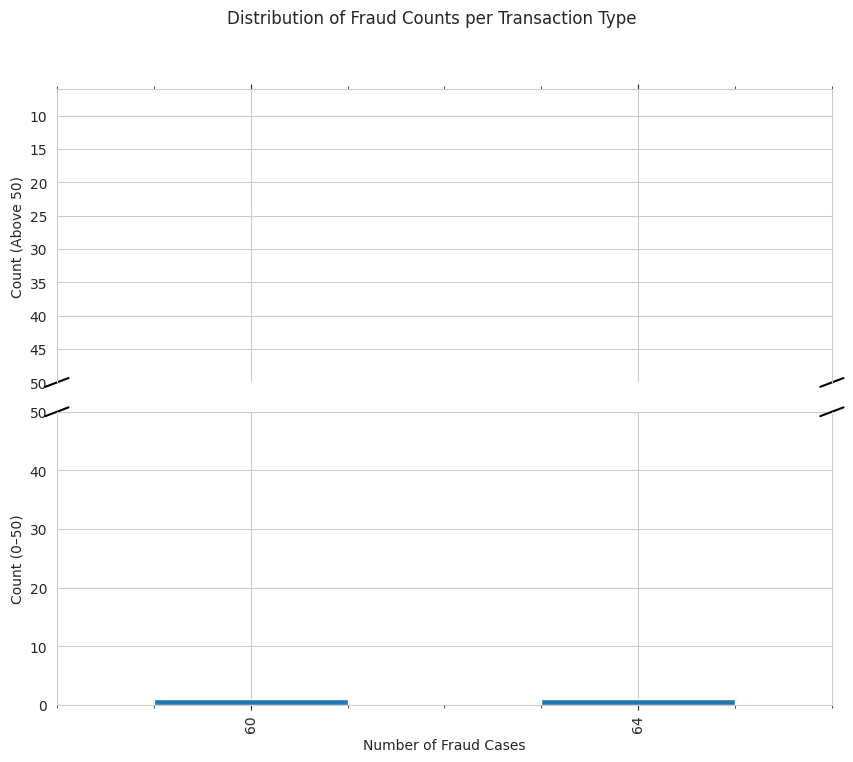

In [ ]:
fraud_df = df[df['isFraud'] == 1]

fraud_counts = fraud_df.groupby('type').size()
fraud_distribution = fraud_counts.value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))
fig.subplots_adjust(hspace=0.1)

fraud_distribution.plot(kind='bar', ax=ax1)
fraud_distribution.plot(kind='bar', ax=ax2)

fig.suptitle('Distribution of Fraud Counts per Transaction Type')

ax1.set_ylim(50, fraud_distribution.max()+5)
ax2.set_ylim(0, 50)

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.xaxis.tick_top()
ax1.tick_params(labeltop=False)
ax2.xaxis.tick_bottom()

d = .015
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((-d, +d), (-d, +d), **kwargs)
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)

kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

ax2.set_ylabel('Count (0–50)')
ax1.set_ylabel('Count (Above 50)')
ax2.set_xlabel('Number of Fraud Cases')
plt.show()

In [ ]:
df[['amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest']].describe()

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
count,1.000000e+05,1.000000e+05,1.000000e+05,1.000000e+05,1.000000e+05
mean,1.815534e+05,8.283566e+05,8.498642e+05,1.102745e+06,1.230714e+06
std,6.168152e+05,2.875843e+06,2.912484e+06,3.531001e+06,3.836813e+06
min,1.800000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.344656e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,7.550210e+04,1.466800e+04,0.000000e+00,1.315374e+05,2.163863e+05
75%,2.092775e+05,1.070410e+05,1.449728e+05,9.458267e+05,1.115200e+06
max,4.669816e+07,4.381886e+07,4.368662e+07,3.281945e+08,3.279981e+08


In [ ]:
df['isFraud'].value_counts()

,count
isFraud,
0,99876
1,124


## Checking Skewness

Original Skewness: 28.00167322675098
Log-Transformed Skewness: -0.5547162403603444


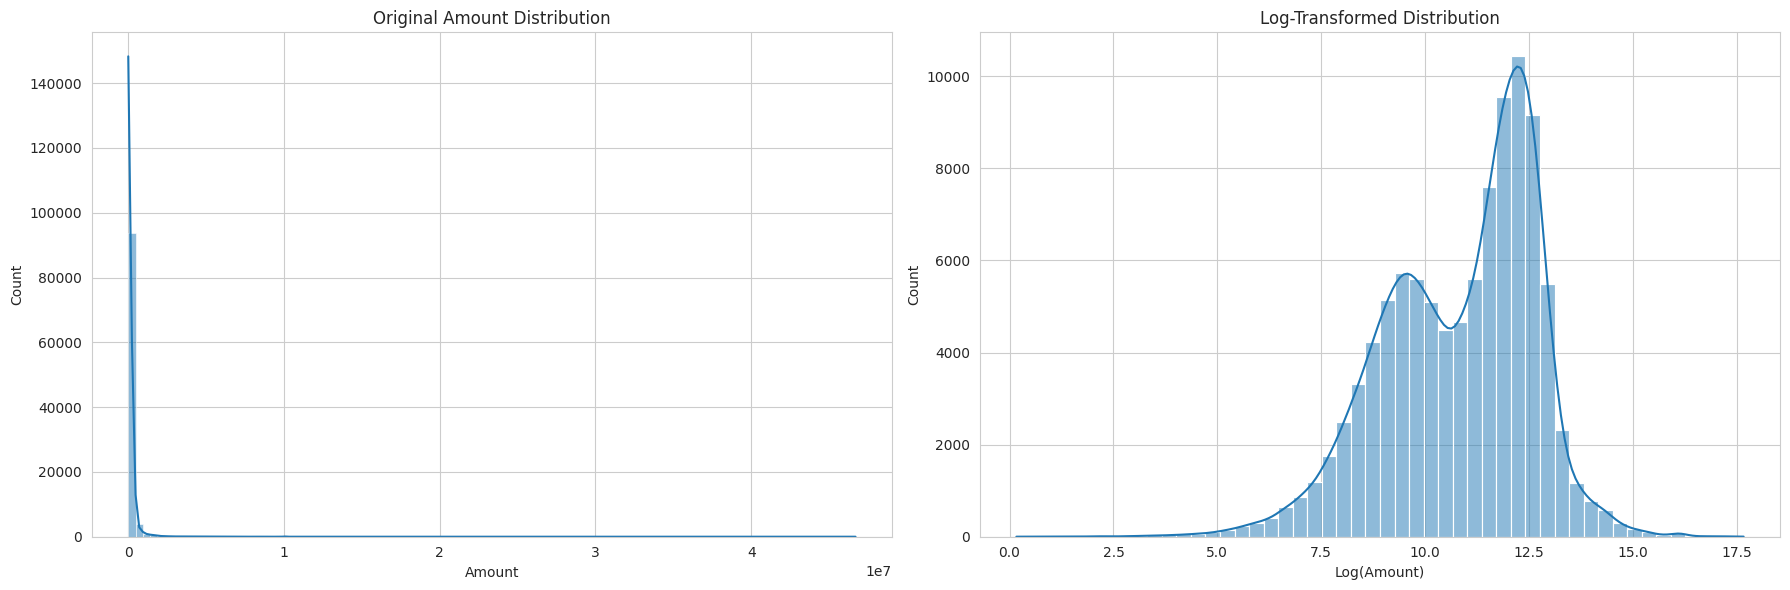

In [ ]:
skewed_data = df['amount']

original_skewness = skew(skewed_data)
print(f"Original Skewness: {original_skewness}")

# Apply a log transformation
log_transformed_data = np.log1p(skewed_data)

# Skewness after transformation
transformed_skewness = skew(log_transformed_data)
print(f"Log-Transformed Skewness: {transformed_skewness}")

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

sns.histplot(skewed_data, bins=100, kde=True, ax=ax[0])
ax[0].set_title('Original Amount Distribution')
ax[0].set_xlabel('Amount')

sns.histplot(log_transformed_data, bins=50, kde=True, ax=ax[1])
ax[1].set_title('Log-Transformed Distribution')
ax[1].set_xlabel('Log(Amount)')

plt.tight_layout()
plt.show()

In [ ]:
total_amount_pivot = pd.pivot_table(df, index=["type"], values='amount', aggfunc=np.sum)

fraud_count_pivot = df[df['isFraud'] == 1].groupby('type').size().to_frame('Fraud_Count')
normal_count_pivot = df[df['isFraud'] == 0].groupby('type').size().to_frame('Normal_Count')

combined_pivot = total_amount_pivot.join([fraud_count_pivot, normal_count_pivot], how='outer')
combined_pivot = combined_pivot.fillna(0)

cm = sns.light_palette("blue", as_cmap=True)
styled_combined_pivot = combined_pivot.style.background_gradient(cmap=cm)

styled_combined_pivot

,amount,Fraud_Count,Normal_Count
type,,,
CASH_IN,3706632501.230000,0.000000,21987
CASH_OUT,6223427440.900000,64.000000,35145
DEBIT,3237089.250000,0.000000,694
PAYMENT,436936888.670000,0.000000,33694
TRANSFER,7785110317.340000,60.000000,8356


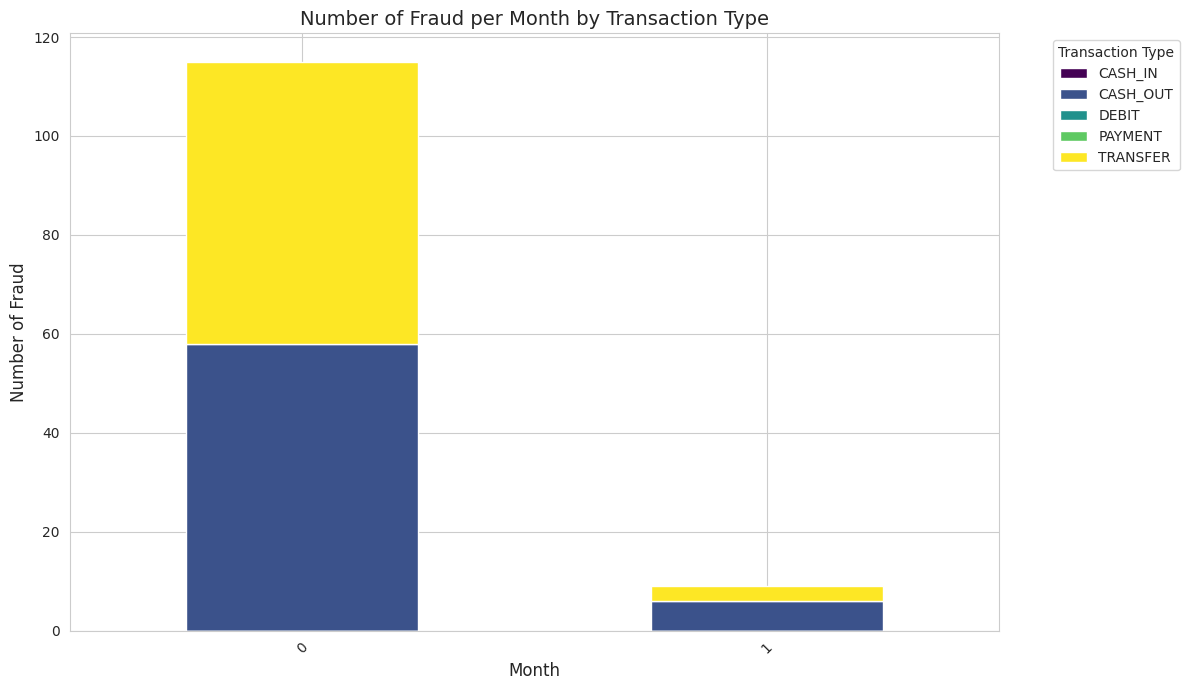

In [ ]:
# Ubah step menjadi hari dan bulan (simulasi waktu)
df['day'] = df['step'] // 24
df['month'] = df['day'] // 30

# Agregasi jumlah fraud per bulan dan tipe transaksi
grouped_data = df.groupby(['month', 'type']).agg({'isFraud': 'sum'}).reset_index()

# Pivot untuk visualisasi
pivot_data = grouped_data.pivot(index='month', columns='type', values='isFraud')

# Plot
sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(12, 7))
pivot_data.plot(kind='bar', ax=ax, stacked=True, colormap='viridis')

plt.title('Number of Fraud per Month by Transaction Type', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Fraud', fontsize=12)
plt.xticks(rotation=45)

plt.legend(title='Transaction Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

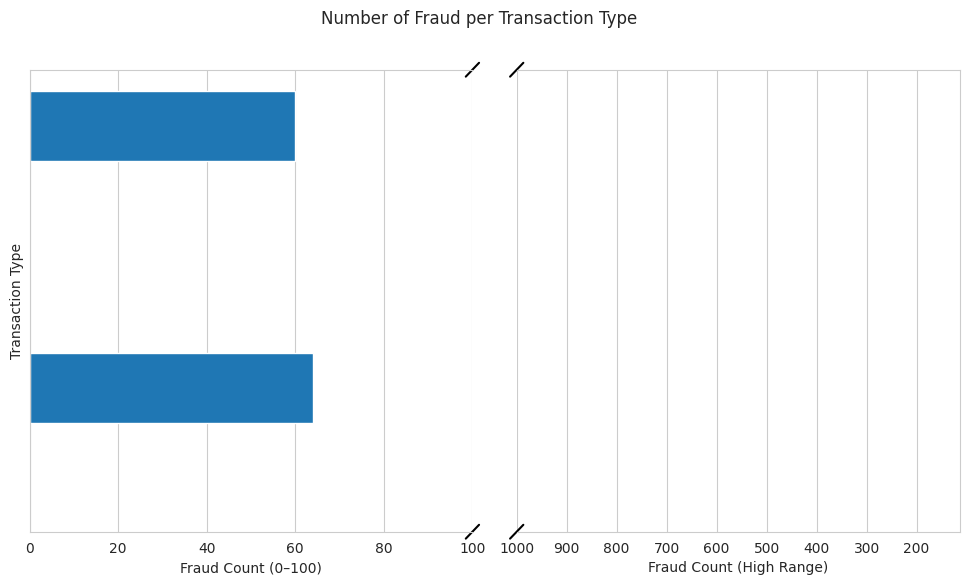

In [ ]:
alerts_per_type = df.groupby('type')['isFraud'].sum().reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(12, 6))
fig.subplots_adjust(wspace=0.1)

ax1.barh(alerts_per_type['type'], alerts_per_type['isFraud'])
ax2.barh(alerts_per_type['type'], alerts_per_type['isFraud'])

ax1.set_xlim(0, 100)
ax2.set_xlim(1000, alerts_per_type['isFraud'].max() + 50)

fig.suptitle('Number of Fraud per Transaction Type')

ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax1.yaxis.tick_left()
ax2.yaxis.tick_right()
ax2.set_yticks([])

d = .015
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
ax1.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (-d, +d), **kwargs)
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)

ax1.set_xlabel('Fraud Count (0–100)')
ax2.set_xlabel('Fraud Count (High Range)')
ax1.set_ylabel('Transaction Type')

plt.show()

In [ ]:
X = df.drop(columns=["isFraud"], axis=1)
y = df["isFraud"]


## Dropping features which are not necessary

In [ ]:
skewed_data = df['amount']

original_skewness = skew(skewed_data)
print(f"Original Skewness: {original_skewness}")

log_transformed_data = np.log1p(skewed_data)

transformed_skewness = skew(log_transformed_data)
print(f"Log-Transformed Skewness: {transformed_skewness}")

df['amount'] = log_transformed_data


Original Skewness: 28.00167322675098
Log-Transformed Skewness: -0.5547162403603444


In [ ]:
num_cols = df.select_dtypes(exclude="object").columns
print(f"We have {len(num_cols)} numerical columns: {num_cols.tolist()}")

categorical_cols = df.select_dtypes(include="object").columns
print(f"We have {len(categorical_cols)} categorical columns: {categorical_cols.tolist()}")

We have 15 numerical columns: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'hour', 'day', 'is_night', 'balance_diff_orig', 'balance_diff_dest', 'is_large_amount', 'month']
We have 3 categorical columns: ['type', 'nameOrig', 'nameDest']


In [ ]:
## Checking for missing values

df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
## Saving a copy of the dataset

df = df.copy(deep=True)
df.head(2)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour,day,is_night,balance_diff_orig,balance_diff_dest,is_large_amount,month
6322570,688,CASH_IN,10.067226,C867750533,8059.0,31616.12,C1026934669,169508.66,145951.53,0,0,16,28,0,-23557.12,-23557.13,0,0
3621196,274,PAYMENT,8.738275,C601099070,0.0,0.00,M701283411,0.00,0.00,0,0,10,11,0,0.00,0.00,0,0


## Data Preprocessing

In [ ]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour,day,is_night,balance_diff_orig,balance_diff_dest,is_large_amount,month
6322570,688,CASH_IN,10.067226,C867750533,8059.00,31616.12,C1026934669,169508.66,145951.53,0,0,16,28,0,-23557.12,-23557.13,0,0
3621196,274,PAYMENT,8.738275,C601099070,0.00,0.00,M701283411,0.00,0.00,0,0,10,11,0,0.00,0.00,0,0
1226256,133,PAYMENT,10.433612,C279540931,18745.72,0.00,M577905776,0.00,0.00,0,0,13,5,0,18745.72,0.00,0,0
2803274,225,CASH_OUT,12.479938,C11675531,20072.00,0.00,C529577791,390253.56,653259.98,0,0,9,9,0,20072.00,263006.42,1,0
3201247,249,CASH_OUT,11.931733,C530649214,20765.00,0.00,C1304175579,252719.19,404732.93,0,0,9,10,0,20765.00,152013.74,0,0


In [ ]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud', 'hour', 'day', 'is_night', 'balance_diff_orig',
       'balance_diff_dest', 'is_large_amount', 'month'],
      dtype='object')

In [ ]:
numeric_cols = df.select_dtypes(exclude="object").columns

numeric_cols

Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'hour', 'day',
       'is_night', 'balance_diff_orig', 'balance_diff_dest', 'is_large_amount',
       'month'],
      dtype='object')

In [ ]:
categorical_cols = df.select_dtypes(include="object").columns

categorical_cols

Index(['type', 'nameOrig', 'nameDest'], dtype='object')

In [ ]:
## Unique columns in df

unique_counts = df[categorical_cols].nunique()
print("Unique columns in the DataFrame: \n", unique_counts)

Unique columns in the DataFrame: 
 type            5
nameOrig    99996
nameDest    92945
dtype: int64


In [ ]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour,day,is_night,balance_diff_orig,balance_diff_dest,is_large_amount,month
count,100000.000000,100000.000000,1.000000e+05,1.000000e+05,1.000000e+05,1.000000e+05,100000.000000,100000.0,100000.000000,100000.00000,100000.00000,1.000000e+05,1.000000e+05,100000.000000,100000.000000
mean,243.229430,10.842548,8.283566e+05,8.498642e+05,1.102745e+06,1.230714e+06,0.001240,0.0,15.307430,9.49675,0.04050,-2.150763e+04,1.279693e+05,0.292290,0.000090
std,142.711863,1.817476,2.875843e+06,2.912484e+06,3.531001e+06,3.836813e+06,0.035192,0.0,4.320558,5.93656,0.19713,1.349263e+05,8.904223e+05,0.454817,0.009486
min,1.000000,0.165514,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0,0.000000,0.00000,0.00000,-1.159761e+06,-1.382713e+06,0.000000,0.000000
25%,155.000000,9.506553,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0,12.000000,6.00000,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000
50%,239.000000,11.231929,1.466800e+04,0.000000e+00,1.315374e+05,2.163863e+05,0.000000,0.0,16.000000,9.00000,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000
75%,335.000000,12.251421,1.070410e+05,1.449728e+05,9.458267e+05,1.115200e+06,0.000000,0.0,19.000000,13.00000,0.00000,1.023795e+04,1.493973e+05,1.000000,0.000000
max,742.000000,17.659215,4.381886e+07,4.368662e+07,3.281945e+08,3.279981e+08,1.000000,0.0,23.000000,30.00000,1.00000,1.000000e+07,1.056878e+08,1.000000,1.000000


In [ ]:
X = df.drop(columns=["isFraud"], axis=1)
y = df["isFraud"]



In [ ]:
numerical_features = X.select_dtypes(exclude="object").columns

numerical_features

Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFlaggedFraud', 'hour', 'day', 'is_night',
       'balance_diff_orig', 'balance_diff_dest', 'is_large_amount', 'month'],
      dtype='object')

In [ ]:
categorical_features = X.select_dtypes(include="object").columns

categorical_features

Index(['type', 'nameOrig', 'nameDest'], dtype='object')

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OrdinalEncoder

## Define the pipeline

num_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler())
    ]
)

cat_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinalencoder", OrdinalEncoder(),
        "scaler", StandardScaler())
    ]
)

In [ ]:
from sklearn.compose import ColumnTransformer

transformer = ColumnTransformer(transformers=[
    ("OrdinalEncoder", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
    ("RobustScaler", RobustScaler(), numerical_features)
], remainder="passthrough")

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
## Transform the datasets

X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)

In [ ]:
print(f"Shape of training data: ", X_train.shape, y_train.shape)
print(f"Shape of testing data: ", X_test.shape, y_test.shape)

Shape of training data:  (80000, 17) (80000,)
Shape of testing data:  (20000, 17) (20000,)


## Baseline Model Creation

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [4,8,16],
    'eta': [0.1,0.2,0.3],
}

xgb = XGBClassifier(eval_metric='logloss', random_state=42)

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=2,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("Best Parameters: ", grid_search.best_params_)

best_model = grid_search.best_estimator_


y_pred = best_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_pred)
print("Test AUC: ", test_auc)


Fitting 2 folds for each of 9 candidates, totalling 18 fits
[CV] END ...............................eta=0.1, max_depth=4; total time=   0.4s
[CV] END ...............................eta=0.1, max_depth=4; total time=   0.5s
[CV] END ...............................eta=0.1, max_depth=8; total time=   0.5s
[CV] END ...............................eta=0.1, max_depth=8; total time=   0.5s
[CV] END ..............................eta=0.1, max_depth=16; total time=   0.5s
[CV] END ..............................eta=0.1, max_depth=16; total time=   0.5s
[CV] END ...............................eta=0.2, max_depth=4; total time=   0.4s
[CV] END ...............................eta=0.2, max_depth=4; total time=   0.4s
[CV] END ...............................eta=0.2, max_depth=8; total time=   0.5s
[CV] END ...............................eta=0.2, max_depth=8; total time=   0.4s
[CV] END ..............................eta=0.2, max_depth=16; total time=   0.5s
[CV] END ..............................eta=0.2, m

## Evaluation of the Model by ROC AUC Curve

Test Set AUC:  0.9875659016045992


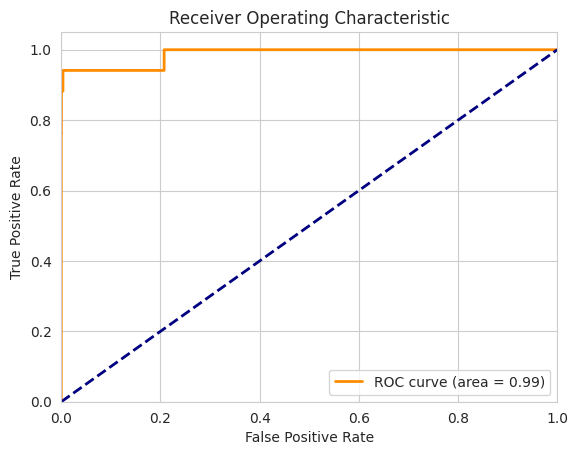

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

test_probabilities = best_model.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)
print("Test Set AUC: ", test_auc)

fpr, tpr, thresholds = roc_curve(y_test, test_probabilities)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % test_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show();

## Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix

[[19980     3]
 [    4    13]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19983
           1       0.81      0.76      0.79        17

    accuracy                           1.00     20000
   macro avg       0.91      0.88      0.89     20000
weighted avg       1.00      1.00      1.00     20000



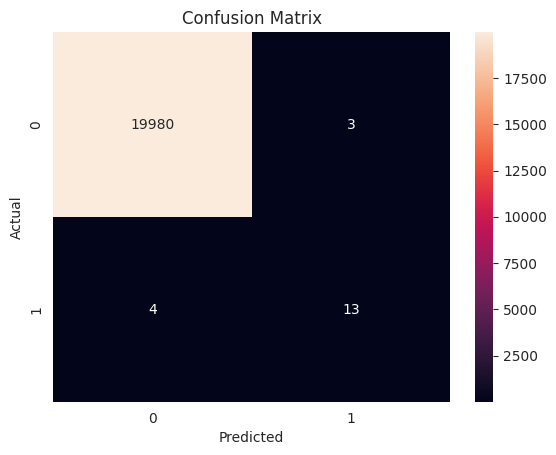

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_best = best_model.predict(X_test)

print(confusion_matrix(y_test, y_pred_best))
print(classification_report(y_test, y_pred_best))

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_best)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Classification Report

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19983
           1       0.68      0.88      0.77        17

    accuracy                           1.00     20000
   macro avg       0.84      0.94      0.88     20000
weighted avg       1.00      1.00      1.00     20000



## Handling the Data Imbalance - Upsampling using SMOTE

In [ ]:
# upsampling using smote
# upsampling using smote

from imblearn.over_sampling import SMOTE
from collections import Counter

counter = Counter(y_train)

print("=============================")

for k,v in counter.items():
    per = 100*v/len(y_train)
    print(f"Class= {k}, n={v} ({per:.2f}%)")

oversample = SMOTE()
X_train_os, y_train_os = oversample.fit_resample(X_train, y_train)

counter = Counter(y_train_os)

print("=============================")

for k,v in counter.items():
    per = 100*v/len(y_train)
    print(f"Class= {k}, n={v} ({per:.2f}%)")

print("=============================")

print("Upsampled data shape: ", X_train_os.shape, y_train_os.shape)

Class= 0, n=79893 (99.87%)
Class= 1, n=107 (0.13%)
Class= 0, n=79893 (99.87%)
Class= 1, n=79893 (99.87%)
Upsampled data shape:  (159786, 17) (159786,)


In [ ]:
from collections import Counter

# Assuming 'y' is your target variable
class_distribution = Counter(y_train_os)

# Print the class distribution
for class_label, count in class_distribution.items():
    print(f"Class {class_label}: {count} samples")

# Check if 'y' is balanced
is_balanced = all(count == class_distribution[y_train_os[0]] for count in class_distribution.values())

if is_balanced:
    print("The target variable 'y' is balanced.")
else:
    print("The target variable 'y' is imbalanced.")

Class 0: 79893 samples
Class 1: 79893 samples
The target variable 'y' is balanced.


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

def fit_classification_models(X, y, test_size=0.2, random_state=42):
    """
    Fit classification models using XGBoost, RandomForest, and ExtraTrees classifiers.

    Parameters:
    -----------
    X : array-like of shape (n_samples, n_features)
        The input data.

    y : array-like of shape (n_samples,)
        The target variable.

    test_size : float, default=0.2
        The proportion of the dataset to include in the test split.

    random_state : int, default=42
        Controls the randomness of the dataset splitting.

    Returns:
    --------
    results : dict
        A dictionary containing the performance metrics for XGBoost, RandomForest, and ExtraTrees classifiers,
        including training and testing results along with confusion matrices and classification reports.
    """

    # Split the dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)

    # Create pipelines for XGBoost, RandomForest, and ExtraTrees classifiers
    pipelines = {
        'XGBoost': Pipeline([('scaler', RobustScaler()), ('classifier', XGBClassifier())]),
        'Random Forest': Pipeline([('scaler', RobustScaler()), ('classifier', RandomForestClassifier())]),
        'ExtraTreesClassifier': Pipeline([('scaler', RobustScaler()), ('classifier', ExtraTreesClassifier())]),
    }

    # Fit and evaluate XGBoost, RandomForest, and ExtraTrees classifiers
    results = {}

    for classifier_name, pipeline in pipelines.items():
        pipeline.fit(X_train, y_train)

        # Training results
        y_train_pred = pipeline.predict(X_train)
        train_precision = round(precision_score(y_train, y_train_pred, average="weighted") * 100, 1)
        train_recall = round(recall_score(y_train, y_train_pred, average="weighted") * 100, 1)
        train_f1 = round(f1_score(y_train, y_train_pred, average="weighted") * 100, 1)
        train_conf_matrix = confusion_matrix(y_train, y_train_pred)
        train_classification_report = classification_report(y_train, y_train_pred, output_dict=True)

        # Testing results
        y_test_pred = pipeline.predict(X_test)
        test_precision = round(precision_score(y_test, y_test_pred, average="weighted") * 100, 1)
        test_recall = round(recall_score(y_test, y_test_pred, average="weighted") * 100, 1)
        test_f1 = round(f1_score(y_test, y_test_pred, average="weighted") * 100, 1)
        test_conf_matrix = confusion_matrix(y_test, y_test_pred)
        test_classification_report = classification_report(y_test, y_test_pred, output_dict=True)

        results[classifier_name] = {
            'training': {
                'precision': train_precision,
                'recall': train_recall,
                'f1-score': train_f1,
                'confusion_matrix': train_conf_matrix,
                'classification_report': train_classification_report
            },
            'testing': {
                'precision': test_precision,
                'recall': test_recall,
                'f1-score': test_f1,
                'confusion_matrix': test_conf_matrix,
                'classification_report': test_classification_report
            }
        }

    return results

Algorithm: XGBoost
      Metric  Training  Testing
0  Precision     100.0    100.0
1     Recall     100.0    100.0
2   F1-score     100.0    100.0




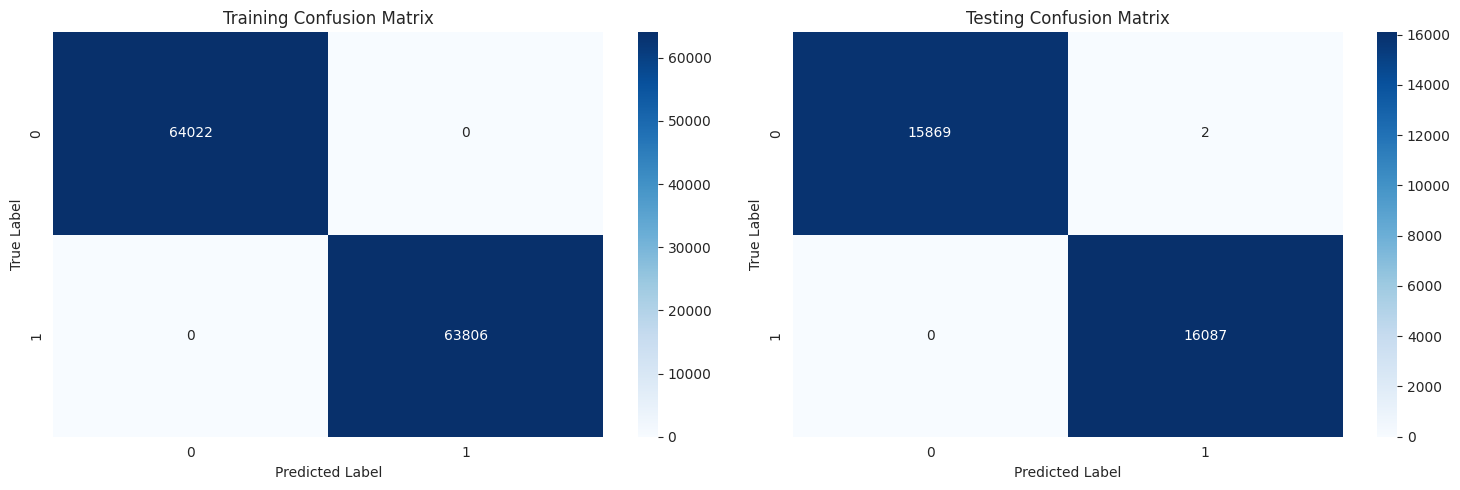

Algorithm: Random Forest
      Metric  Training  Testing
0  Precision     100.0    100.0
1     Recall     100.0    100.0
2   F1-score     100.0    100.0




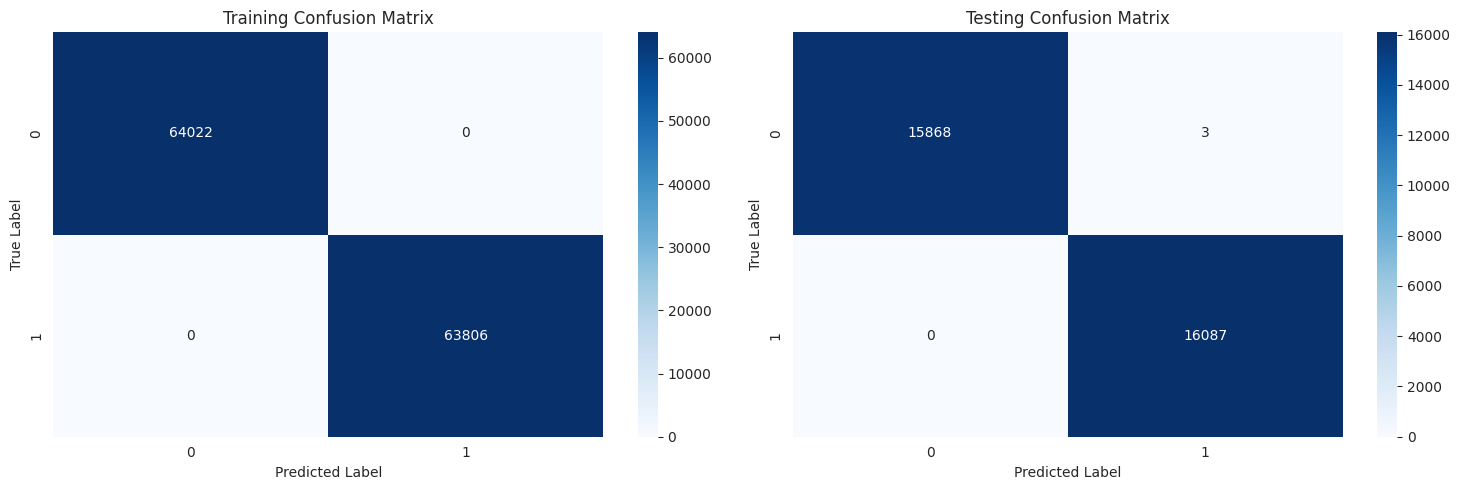

Algorithm: ExtraTreesClassifier
      Metric  Training  Testing
0  Precision     100.0    100.0
1     Recall     100.0    100.0
2   F1-score     100.0    100.0




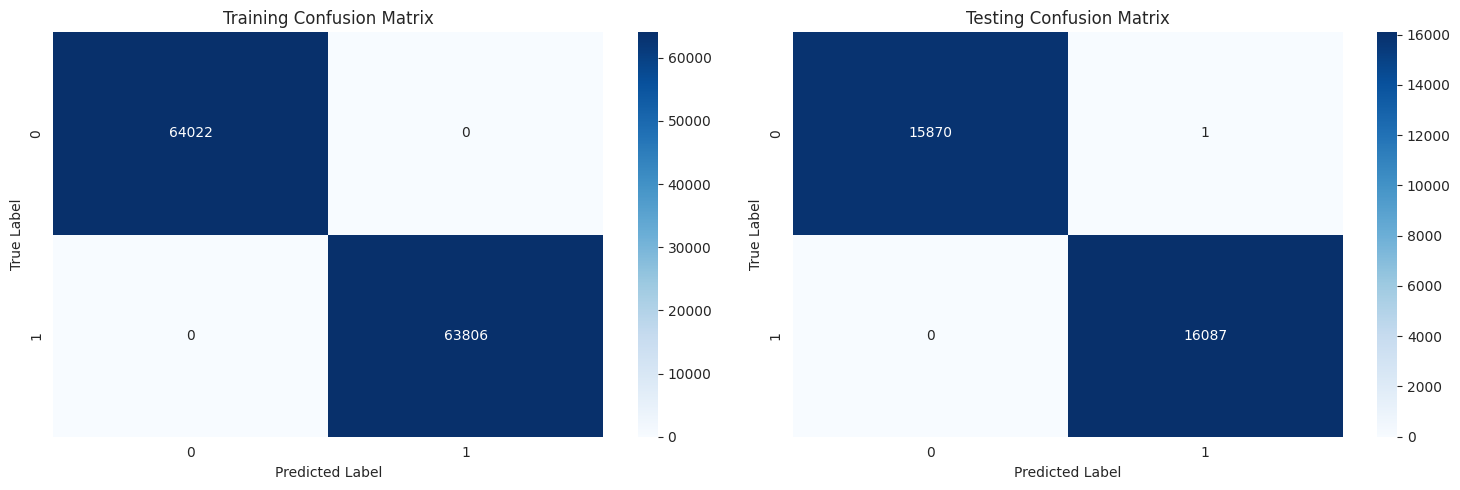

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Call fit_classification_models() function to generate results
results = fit_classification_models(X_train_os, y_train_os)

# Plot confusion matrices and display DataFrame for each algorithm
for classifier_name, metrics in results.items():
    print(f"Algorithm: {classifier_name}")

    # Display DataFrame
    df = pd.DataFrame({
        'Metric': ['Precision', 'Recall', 'F1-score'],
        'Training': [metrics['training']['precision'], metrics['training']['recall'], metrics['training']['f1-score']],
        'Testing': [metrics['testing']['precision'], metrics['testing']['recall'], metrics['testing']['f1-score']]
    })
    print(df)
    print("\n")

    # Plot confusion matrices
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Training confusion matrix
    sns.heatmap(metrics['training']['confusion_matrix'], annot=True, fmt='d', cmap='Blues', ax=axes[0])
    axes[0].set_title('Training Confusion Matrix')
    axes[0].set_xlabel('Predicted Label')
    axes[0].set_ylabel('True Label')

    # Testing confusion matrix
    sns.heatmap(metrics['testing']['confusion_matrix'], annot=True, fmt='d', cmap='Blues', ax=axes[1])
    axes[1].set_title('Testing Confusion Matrix')
    axes[1].set_xlabel('Predicted Label')
    axes[1].set_ylabel('True Label')

    plt.tight_layout()
    plt.show()

In [ ]:
# Initialize a list to store the scores
all_scores = []

# Iterate over the results
for classifier_name, metrics in results.items():
    # Append the scores to the list
    all_scores.append({
        'Algorithm': classifier_name,
        'Training Precision': metrics['training']['precision'],
        'Testing Precision': metrics['testing']['precision'],
        'Training Recall': metrics['training']['recall'],
        'Testing Recall': metrics['testing']['recall'],
        'Training F1-score': metrics['training']['f1-score'],
        'Testing F1-score': metrics['testing']['f1-score']
    })

# Create a DataFrame from the scores list
scores_df = pd.DataFrame(all_scores)

# Sort the DataFrame by the 'Testing F1-score' column in descending order
scores_sorted = scores_df.sort_values(by='Testing F1-score', ascending=False)

# Display the sorted DataFrame
scores_sorted

,Algorithm,Training Precision,Testing Precision,Training Recall,Testing Recall,Training F1-score,Testing F1-score
0,XGBoost,100.0,100.0,100.0,100.0,100.0,100.0
1,Random Forest,100.0,100.0,100.0,100.0,100.0,100.0
2,ExtraTreesClassifier,100.0,100.0,100.0,100.0,100.0,100.0
